# Example #5: Power saturation

QMix calculates the tunneling currents for any signal power, not just in the small-signal limit. This notebook uses this to simulate the saturation of an SIS mixer, and compares it with measurements:

1. **LO power:** the gain and noise of the mixer as the LO power is increased, compared with hot/cold measurements.
2. **RF power:** the compression of the gain by a strong RF signal, compared with the measured IF output power.

## Part 1: LO power

The data are from device #5.6 (the same device as in Example #3, Garrett, 2018), measured at 255 GHz with 9 LO power levels. The example data are in ``example-data/lo-saturation/``:

- ``dciv.csv``, ``dcif.csv``: the unpumped DC I-V curve and IF power.
- ``levelN_iv.csv``, ``levelN_if-hot.csv``, ``levelN_if-cold.csv``: the pumped I-V curve and the IF power with hot and cold loads at power level N = 0-8. The power levels are not in order: levels 0-5 increase, and levels 6-8 are below level 0.

In [1]:
%matplotlib inline

import contextlib
import io
import glob
import os

import numpy as np
import matplotlib.pyplot as plt

import qmix

# https://github.com/garrettj403/SciencePlots
import scienceplots
plt.style.use(['science', 'notebook'])

In [2]:
params = dict(delimiter = ',',           # CSV files
              usecols = (0, 1),
              skip_header = 1,
              v_fmt = 'mV',              # units
              i_fmt = 'mA',
              area = 1.5,                # junction area in um^2
              vgap_threshold = 105e-6,   # gap voltage defined at this current
              filter_data = True,        # Savitzky-Golay filter
              filter_nwind = 21,
              verbose = False)


def load(filename):
    """Load a CSV file (bias voltage in mV, current in mA or IF power)."""
    return np.genfromtxt(filename, delimiter=',', skip_header=1)


def quiet():
    """Hide the printout of the impedance recovery."""
    return contextlib.redirect_stdout(io.StringIO())


# Hot and cold load temperatures (K), from the lab notes of this measurement
params.update(t_hot=293., t_cold=77.)

## Importing the data

In [3]:
D = 'example-data/lo-saturation/'
FREQ = 255.0  # LO frequency (GHz)

with quiet():
    dciv = qmix.exp.DCData(load(D + 'dciv.csv'), load(D + 'dcif.csv'), **params)
print("Rn = {:.2f} ohms, Vgap = {:.3f} mV".format(dciv.rn, dciv.vgap * 1e3))

pumps = []
for n in range(9):
    with quiet():
        pump = qmix.exp.PumpedData(load(D + 'level{}_iv.csv'.format(n)), dciv,
                                   load(D + 'level{}_if-hot.csv'.format(n)), load(D + 'level{}_if-cold.csv'.format(n)),
                                   freq=FREQ, **params)
    pumps.append(pump)

Rn = 14.01 ohms, Vgap = 2.690 mV


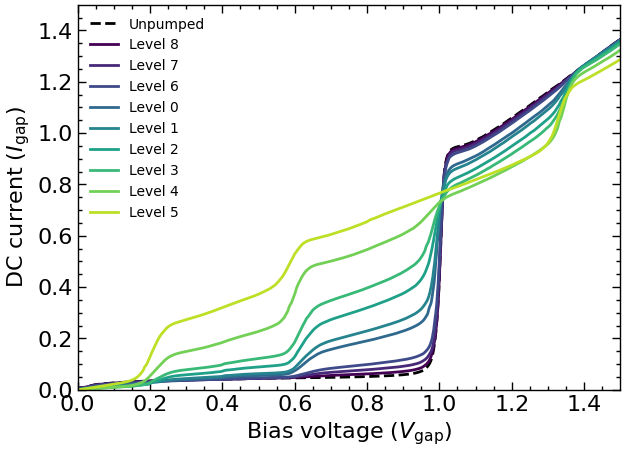

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dciv.voltage, dciv.current, 'k--', label='Unpumped')
by_power = [8, 7, 6, 0, 1, 2, 3, 4, 5]  # power levels, from lowest to highest LO power
colors = plt.cm.viridis(np.linspace(0, 0.9, len(by_power)))
for n, color in zip(by_power, colors):
    ax.plot(pumps[n].voltage, pumps[n].current, c=color, label='Level {}'.format(n))
ax.set_xlabel(r'Bias voltage ($V_\mathrm{gap}$)')
ax.set_ylabel(r'DC current ($I_\mathrm{gap}$)')
ax.set_xlim(0, 1.5)
ax.set_ylim(0, 1.5)
ax.legend(fontsize=10);

## The embedding circuit

``PumpedData`` recovers the embedding impedance and voltage at each power level. In principle, the embedding impedance shouldn't depend on the LO power. At 255 GHz, however, the recovery is not well conditioned, and the recovered impedance drifts as the LO power increases:

In [5]:
print("Level   recovered zt (Rn)   vt (Vgap)")
for n, pump in enumerate(pumps):
    print("{:4d}    {:5.2f}{:+5.2f}j         {:.3f}   {}".format(n, pump.zt.real, pump.zt.imag, pump.vt,
                                                               '' if pump.fit_good else '(bad fit)'))

Level   recovered zt (Rn)   vt (Vgap)
   0     0.26-0.69j         0.477   
   1     0.26-0.66j         0.539   
   2     0.19-0.44j         0.596   
   3     0.07-0.27j         0.599   
   4     0.00-0.90j         0.982   (bad fit)
   5     0.00-0.17j         0.984   (bad fit)
   6     0.27-0.75j         0.280   
   7     0.28-0.74j         0.210   
   8     0.27-0.83j         0.136   


Instead, we will fix the embedding impedance at the average of the two lowest power levels (0 and 1), where the photon steps are well defined, and fit only the Thevenin voltage to each pumped I-V curve. The fit uses the first photon step below the gap and the smeared response function (``dciv.resp_smear``).

In [6]:
from scipy.optimize import minimize_scalar
from qmix.circuit import EmbeddingCircuit
from qmix.harmonic_balance import harmonic_balance
from qmix.qtcurrent import qtcurrent

zt = np.mean([pumps[0].zt, pumps[1].zt])
vph = pumps[0].vph  # photon voltage (normalized)
print("Fixed embedding impedance: {:.3f} Rn".format(zt))

v_fit = np.linspace(1 - vph + 0.03, 0.97, 25)  # first photon step below the gap


def simulate_iv(vt):
    """Simulated DC current at v_fit for a Thevenin voltage vt."""
    cct = EmbeddingCircuit(1, 1, vb_npts=len(v_fit), vgap=dciv.vgap, rn=dciv.rn)
    cct.vb = v_fit
    cct.freq[1] = vph
    cct.vt[1, 1] = vt
    cct.zt[1, 1] = zt
    vj = harmonic_balance(cct, dciv.resp_smear, num_b=25, verbose=False)
    return qtcurrent(vj, cct, dciv.resp_smear, 0., num_b=25, verbose=False)


vt_fit, iv_error = [], []
for pump in pumps:
    i_meas = np.interp(v_fit, pump.voltage, pump.current)
    result = minimize_scalar(lambda vt: np.mean((simulate_iv(vt) - i_meas) ** 2),
                             bounds=(0.02, 2.), method='bounded')
    vt_fit.append(result.x)
    iv_error.append(np.sqrt(result.fun))
    # Use this embedding circuit from now on
    pump.vt, pump.zt = result.x, zt
vt_fit = np.array(vt_fit)

print("\nLevel   vt (Vgap)   rms I-V error (Igap)")
for n, (vt, err) in enumerate(zip(vt_fit, iv_error)):
    print("{:4d}    {:.3f}       {:.4f}".format(n, vt, err))

Fixed embedding impedance: 0.260-0.675j Rn

Level   vt (Vgap)   rms I-V error (Igap)
   0    0.471       0.0032
   1    0.540       0.0029
   2    0.687       0.0064
   3    0.805       0.0091
   4    1.053       0.0088
   5    1.358       0.0052
   6    0.258       0.0093
   7    0.185       0.0109
   8    0.095       0.0120


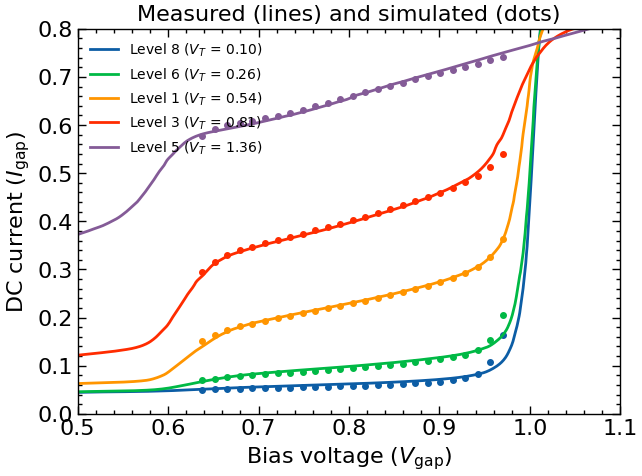

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for n in np.argsort(vt_fit)[::2]:
    line, = ax.plot(pumps[n].voltage, pumps[n].current, label='Level {} ($V_T$ = {:.2f})'.format(n, vt_fit[n]))
    ax.plot(v_fit, simulate_iv(vt_fit[n]), 'o', c=line.get_color(), ms=4)
ax.set_xlabel(r'Bias voltage ($V_\mathrm{gap}$)')
ax.set_ylabel(r'DC current ($I_\mathrm{gap}$)')
ax.set_xlim(0.5, 1.1)
ax.set_ylim(0, 0.8)
ax.set_title('Measured (lines) and simulated (dots)')
ax.legend(fontsize=10);

With one fixed impedance, the Thevenin voltage alone reproduces the first photon step at every power level.

## Gain and noise vs LO power

Now, ``mixer_noise`` simulates the mixer at each power level with this embedding circuit (see Example #3). The gain and noise of the RF/optics stage in front of the mixer don't depend on the LO power, so we fit them only to the three lowest power levels (0-2), at the best bias voltage of each level, and keep them fixed:

- gain: G = G_RF G_mix
- noise: T_rx = T_RF + (T_mix + T_IF / G_mix) / G_RF

The dependence on the LO power is then a prediction of the simulation.

In [8]:
F_IF, TEMP = 5., 5.1  # IF frequency (GHz) and physical temperature (K)

rows = []
for pump in pumps:
    with quiet():
        noise = pump.mixer_noise(F_IF, temp=TEMP, smeared=True, voltage=np.linspace(0.1, 1.2, 111),
                                 fit_range=(pump.v_best - vph / 4, pump.v_best + vph / 4))
    i = np.argmin(np.abs(noise.voltage - pump.v_best))
    rows.append(dict(g_mix=noise.g_mix[i], t_mix=noise.t_mix[i], t_if=noise.t_if,
                     g_meas=noise.gain_meas[i], tn_meas=noise.tn_meas[i]))

g_mix = np.array([r['g_mix'] for r in rows])
t_mix = np.array([r['t_mix'] for r in rows])
t_if = np.array([r['t_if'] for r in rows])
g_meas = np.array([r['g_meas'] for r in rows])
tn_meas = np.array([r['tn_meas'] for r in rows])

g_rf = np.mean(g_meas[:3] / g_mix[:3])
t_rf = np.mean(tn_meas[:3] - (t_mix[:3] + t_if[:3] / g_mix[:3]) / g_rf)
g_model = g_rf * g_mix
tn_model = t_rf + (t_mix + t_if / g_mix) / g_rf
print("RF/optics stage (levels 0-2): G_RF = {:.3f}, T_RF = {:.1f} K\n".format(g_rf, t_rf))

print("Level   vt     G (meas)  G (model)  ratio   Tn (meas)  Tn (model)")
for n in np.argsort(vt_fit):
    print("{:4d}   {:.2f}   {:.3f}     {:.3f}      {:.2f}    {:6.1f} K   {:6.1f} K".format(
          n, vt_fit[n], g_meas[n], g_model[n], g_meas[n] / g_model[n], tn_meas[n], tn_model[n]))

RF/optics stage (levels 0-2): G_RF = 0.786, T_RF = 48.1 K

Level   vt     G (meas)  G (model)  ratio   Tn (meas)  Tn (model)
   8   0.10   0.088     0.067      1.33     224.2 K    190.5 K
   7   0.18   0.188     0.195      0.97     109.9 K     92.7 K
   6   0.26   0.266     0.284      0.93      84.2 K     76.4 K
   0   0.47   0.365     0.364      1.00      64.3 K     65.8 K
   1   0.54   0.360     0.360      1.00      66.3 K     66.6 K
   2   0.69   0.345     0.345      1.00      70.7 K     69.0 K
   3   0.81   0.335     0.344      0.97      76.2 K     70.7 K
   4   1.05   0.293     0.383      0.77     110.5 K     86.8 K
   5   1.36   0.163     0.174      0.94     135.4 K    110.0 K


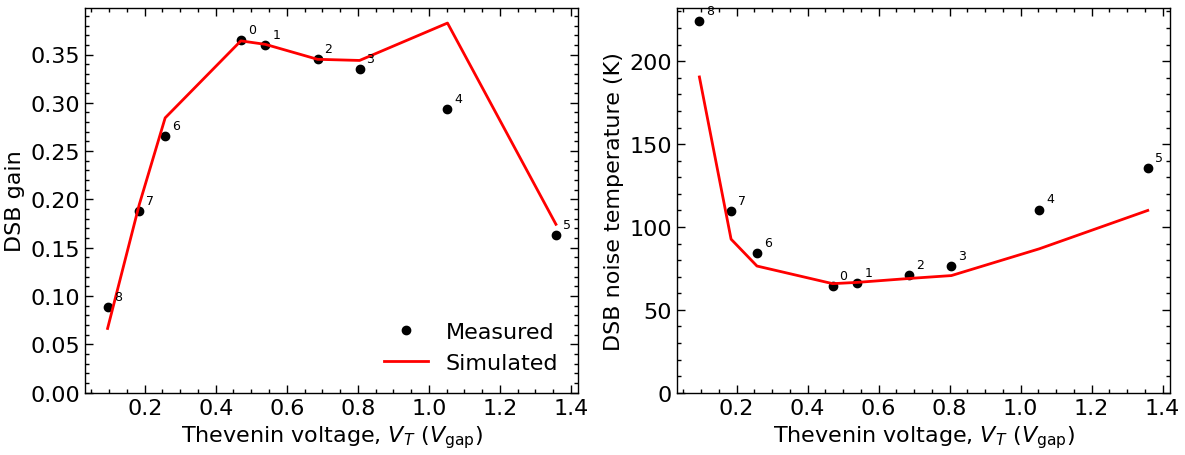

In [9]:
order = np.argsort(vt_fit)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(vt_fit[order], g_meas[order], 'ko', label='Measured')
ax[0].plot(vt_fit[order], g_model[order], 'r-', label='Simulated')
ax[0].set_ylabel('DSB gain')
ax[1].plot(vt_fit[order], tn_meas[order], 'ko', label='Measured')
ax[1].plot(vt_fit[order], tn_model[order], 'r-', label='Simulated')
ax[1].set_ylabel('DSB noise temperature (K)')
for a in ax:
    a.set_xlabel(r'Thevenin voltage, $V_T$ ($V_\mathrm{gap}$)')
    a.set_ylim(bottom=0)
    for n in range(9):
        a.annotate(str(n), (vt_fit[n], (g_meas if a is ax[0] else tn_meas)[n]),
                   textcoords='offset points', xytext=(5, 5), fontsize=9)
ax[0].legend();

The numbers next to the points are the power levels. With the RF stage fixed, the simulation predicts how the gain rises and then saturates with LO power, to within a few percent for most levels. The exceptions are level 4, where the measured gain is ~23% below the simulation, and the nearly unpumped level 8. The simulated noise temperature matches the fitted levels (0-2) but is too low at both ends: the measured noise increases faster than the simulation predicts as the LO power moves away from the optimum (e.g., 111 K measured vs 87 K simulated at level 4).

The gain at each power level can also be compared across the whole bias range:

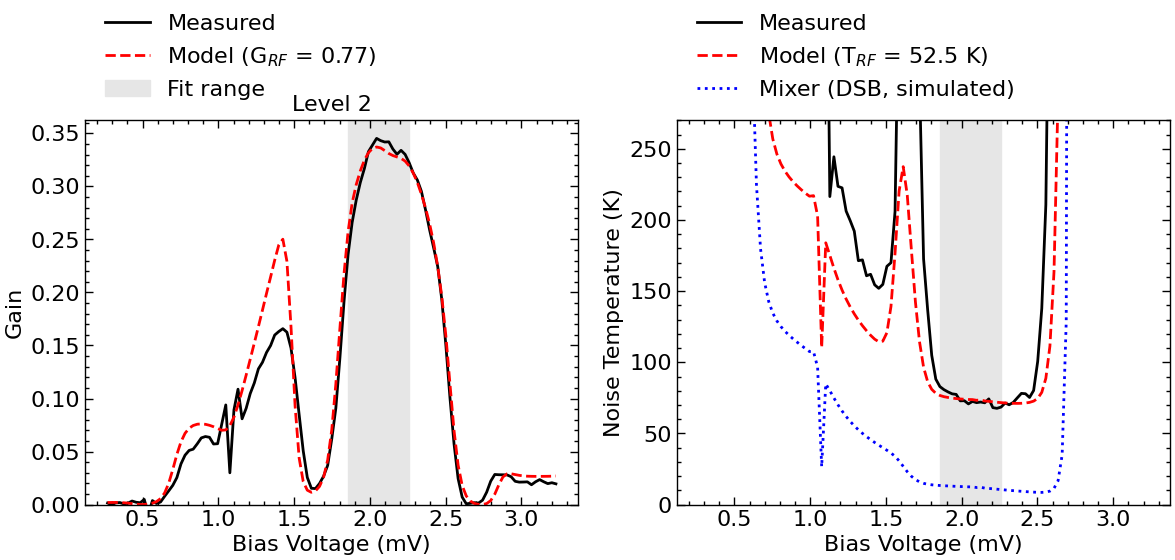

In [10]:
n = 2
with quiet():
    noise = pumps[n].mixer_noise(F_IF, temp=TEMP, smeared=True, voltage=np.linspace(0.1, 1.2, 111))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pumps[n].plot_mixer_noise(noise, ax=ax)
ax[0].set_title('Level {}'.format(n));

## Part 2: RF power

In a real receiver, a strong RF signal (e.g., a bright spectral line) also saturates the mixer. With multi-tone spectral domain analysis, the RF signal can be simulated as a tone of any power, so this saturation is included automatically (see Garrett et al., 2019, for simulations of this mixer).

In this measurement, the mixer was pumped by an LO at 229.5 GHz (a Gubbins source), and a second strong source at 232.757 GHz (a Gunn oscillator) was used as the RF signal. The RF power was varied by rotating a wire grid from 0 to 90 degrees, and the IF output at 3.257 GHz was measured with a spectrum analyzer. The DC I-V curve has the same normal resistance and gap voltage as the device above, so this is most likely device #5.6 again. The example data are in ``example-data/rf-saturation/``:

- ``dciv.csv``, ``dcif.csv``: the unpumped DC I-V curve and IF power.
- ``lo-only_iv.csv``, ``rf-only_iv.csv``, ``lo-and-rf_iv.csv``: the pumped I-V curves with the LO alone, the RF source alone (grid at 0 degrees), and both.
- ``spectrum_gridN.csv``: the IF spectrum with both sources, with the grid at N = 0, 10, ..., 90 degrees.

### The embedding circuits of the two sources

As in Example #3, the embedding circuit of each source is recovered from its own pumped I-V curve. Together, they then predict the I-V curve with both sources, and the IF output, with no free parameters (other than the IF load impedance).

In [11]:
D2 = 'example-data/rf-saturation/'
F_LO, F_RF = 229.5, 232.757  # GHz

with quiet():
    dciv2 = qmix.exp.DCData(load(D2 + 'dciv.csv'), load(D2 + 'dcif.csv'), **params)
    lo = qmix.exp.PumpedData(load(D2 + 'lo-only_iv.csv'), dciv2, freq=F_LO, analyze_if=False, **params)
    rf = qmix.exp.PumpedData(load(D2 + 'rf-only_iv.csv'), dciv2, freq=F_RF, analyze_if=False, **params)
    both = qmix.exp.PumpedData(load(D2 + 'lo-and-rf_iv.csv'), dciv2, freq=F_LO, analyze_iv=False,
                               analyze_if=False, **params)

print("Rn = {:.2f} ohms, Vgap = {:.3f} mV".format(dciv2.rn, dciv2.vgap * 1e3))
for name, p in (('LO', lo), ('RF', rf)):
    print("{}: vt = {:.3f} Vgap, zt = {:.2f} Rn".format(name, p.vt, p.zt))

Rn = 14.01 ohms, Vgap = 2.690 mV
LO: vt = 0.533 Vgap, zt = 0.50-0.58j Rn
RF: vt = 0.365 Vgap, zt = 0.50-0.23j Rn


The IF is at the difference frequency, f_RF - f_LO = 3.257 GHz. QMix matches frequencies after rounding them to 4 decimal places (normalized to the gap frequency), so the normalized frequencies are rounded first, to make sure that the IF is exactly f_RF - f_LO.

The IF is a third tone with no source (``vt = 0``). The current that the junction generates at the IF flows through the IF load and creates an IF voltage across the junction. The IF frequency is low, so the IF tone needs many terms in the Bessel function sums (``num_b``).

The IF load impedance at the junction is not known: it is set by the IF circuit of the device (the tuning circuit and an IF transformer to the 50 ohm IF amplifier). However, the IF voltage smooths the photon steps of the I-V curve with both sources, so we can find the IF load from this curve:

In [12]:
fgap = dciv2.fgap / 1e9
f1 = round(F_LO / fgap, 4)
f2 = round(F_RF / fgap, 4)
f3 = round(f2 - f1, 4)
NUM_B = (8, 10, 45)


def simulate_2(v, vt_rf, z_if):
    """3-tone simulation (LO, RF and IF), with an IF load of z_if ohms.
    Returns the DC current, the IF power delivered to the IF load
    (normalized) and the embedding circuit."""
    cct = EmbeddingCircuit(3, 1, vb_npts=len(v), vgap=dciv2.vgap, rn=dciv2.rn)
    cct.vb = v
    cct.freq[1], cct.vt[1, 1], cct.zt[1, 1] = f1, lo.vt, lo.zt
    cct.freq[2], cct.vt[2, 1], cct.zt[2, 1] = f2, vt_rf, rf.zt
    cct.freq[3], cct.vt[3, 1], cct.zt[3, 1] = f3, 0., z_if / dciv2.rn
    with quiet():
        vj = harmonic_balance(cct, dciv2.resp_smear, num_b=NUM_B, verbose=False, max_it=50)
    idc = qtcurrent(vj, cct, dciv2.resp_smear, 0., num_b=NUM_B, verbose=False).real
    p_if = 0.5 * np.abs(vj[3, 1]) ** 2 * np.real(1 / (z_if / dciv2.rn))
    return idc, p_if, cct


v = np.linspace(0.05, 1.3, 126)
below_gap = v < 1
i_meas2 = np.interp(v, both.voltage, both.current)

z_if_values = np.array([2., 3., 4., 5., 7., 10., 25., 50.])  # ohms
i_sim, error = [], []
for z_if in z_if_values:
    i, _, cct = simulate_2(v, rf.vt, z_if)
    i_sim.append(i)
    error.append(np.sqrt(np.mean((i - i_meas2)[below_gap] ** 2)))
z_best = z_if_values[np.argmin(error)]

print("IF load (ohms):  ", z_if_values)
print("rms I-V error:   ", np.round(error, 4))
print("Best IF load: {:.0f} ohms".format(z_best))
print("\nAvailable power: LO {:.1f} dBm, RF {:.1f} dBm".format(cct.available_power(1, units='dBm'),
                                                              cct.available_power(2, units='dBm')))

IF load (ohms):   [ 2.  3.  4.  5.  7. 10. 25. 50.]
rms I-V error:    [0.0094 0.0067 0.0053 0.0055 0.0087 0.0143 0.0312 0.0409]
Best IF load: 4 ohms

Available power: LO -44.4 dBm, RF -47.6 dBm


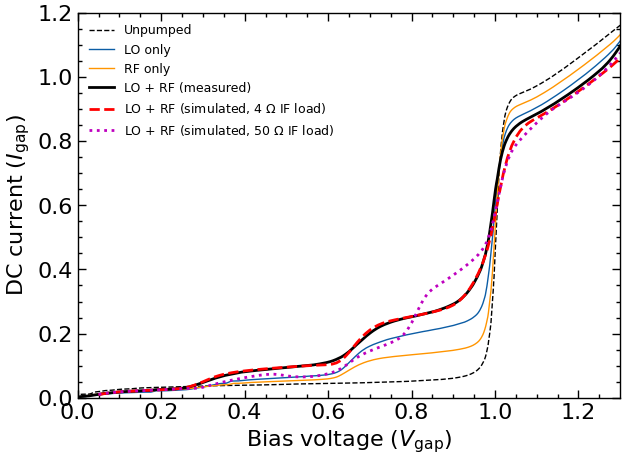

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dciv2.voltage, dciv2.current, 'k--', lw=1, label='Unpumped')
ax.plot(lo.voltage, lo.current, c='C0', lw=1, label='LO only')
ax.plot(rf.voltage, rf.current, c='C2', lw=1, label='RF only')
ax.plot(both.voltage, both.current, 'k', label='LO + RF (measured)')
ax.plot(v, i_sim[np.argmin(error)], 'r--', label=r'LO + RF (simulated, {:.0f} $\Omega$ IF load)'.format(z_best))
ax.plot(v, i_sim[-1], 'm:', label=r'LO + RF (simulated, 50 $\Omega$ IF load)')
ax.set_xlabel(r'Bias voltage ($V_\mathrm{gap}$)')
ax.set_ylabel(r'DC current ($I_\mathrm{gap}$)')
ax.set_xlim(0, 1.3)
ax.set_ylim(0, 1.2)
ax.legend(fontsize=9);

The RF signal is almost as strong as the LO, so the I-V curve with both sources is not simply the sum of the two. With an IF load of a few ohms, the simulation reproduces it very closely, from the two single-source curves alone. With a 50 ohm IF load, the IF voltage is ~3 times larger, and it smooths the photon steps far more than measured (e.g., the current rises ~0.17 Vgap below the gap, the amplitude of the IF voltage).

### The measured IF output

The IF output was measured with a spectrum analyzer at each grid angle. The IF peak is at ~3.24 GHz (the spectra have a resolution of 20 MHz):

Grid angle (deg):   [ 0 10 20 30 40 50 60 70 80 90]
IF peak (dBm):      [ -6.42  -6.43  -6.62  -7.16  -8.12 -10.13 -13.2  -18.88 -29.54 -41.26]


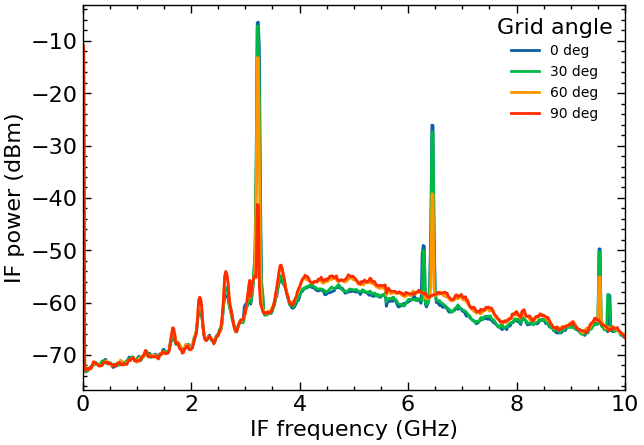

In [14]:
angles = np.arange(0, 100, 10)
p_out = []
fig, ax = plt.subplots(figsize=(7, 5))
for angle in angles:
    spectrum = load(D2 + 'spectrum_grid{}.csv'.format(angle))
    near_if = (spectrum[:, 0] > 2.5) & (spectrum[:, 0] < 4.)
    p_out.append(spectrum[near_if, 1].max())
    if angle % 30 == 0:
        ax.plot(spectrum[:, 0], spectrum[:, 1], label='{} deg'.format(angle))
p_out = np.array(p_out)
ax.set_xlabel('IF frequency (GHz)')
ax.set_ylabel('IF power (dBm)')
ax.set_xlim(0, 10)
ax.legend(title='Grid angle', fontsize=10);

print("Grid angle (deg):  ", angles)
print("IF peak (dBm):     ", p_out)

### The RF power

The RF source is linearly polarized and passes through the wire grid, and the mixer only receives one polarization. Rotating the grid by an angle $\theta$ therefore reduces the field by $\cos\theta$ twice: once in the grid, and once at the mixer, which gives a power of

$$P_{RF}(\theta) = P_{RF}(0) \cos^4\theta.$$

This is confirmed by a measurement on the same setup a month earlier (2017-04-10), where the pumped I-V curve with only the RF source was measured at each grid angle: the Thevenin voltages recovered from these curves give $|V_T(\theta) / V_T(0)|^2$ = 0.18, 0.07 and 0.012 at 50, 60 and 70 degrees, compared to $\cos^4\theta$ = 0.17, 0.06 and 0.014. (At 90 degrees, the measured IF power is set by leakage through the grid, so this point is not used.)

### Gain compression

Now we simulate the IF output power at each grid angle, with the Thevenin voltage of the RF source scaled by $\cos^2\theta$, for the IF load found above and for 50 ohms. The bias voltage of the spectra was not recorded, so the simulations are done at three bias voltages across the first photon step below the gap (2.0-2.3 mV); the shaded areas show the range. The gain is shown relative to its value with the weakest RF signal (80 degrees), for both the measurement and the simulations:

1 dB compression point (dBm):
  measured:                -67.5
  simulated,  4 ohm load: not reached (above -47.6)
  simulated, 50 ohm load: -62.7 to -57.5
Compression at the highest RF power (dB):
  measured:                -7.3
  simulated,  4 ohm load: -1.0 to -0.9
  simulated, 50 ohm load: -7.8 to -6.8


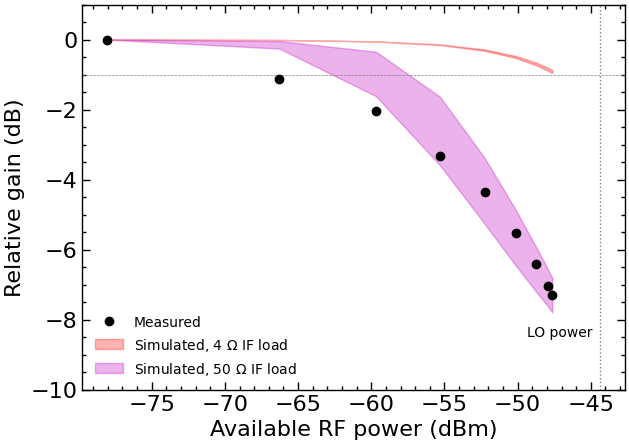

In [15]:
angles = angles[:-1]  # without 90 deg
p_out = p_out[:-1]
transmission = np.cos(np.radians(angles)) ** 4
p_rf = cct.available_power(2, units='dBm') + 10 * np.log10(transmission)  # available RF power (dBm)
v_bias = np.array([0.75, 0.80, 0.85])

gain_meas = p_out - p_rf
gain_meas -= gain_meas[-1]

gain_sim = {}
for z_if in (z_best, 50.):
    p_if = np.array([simulate_2(v_bias, rf.vt * np.sqrt(t), z_if)[1] for t in transmission])  # [angle, bias]
    g = 10 * np.log10(p_if) - p_rf[:, None]
    gain_sim[z_if] = g - g[-1]


def p_1db(gain):
    """RF power where the gain has dropped by 1 dB (interpolated; NaN if it
    doesn't drop that far)."""
    if gain.min() > -1:
        return np.nan
    return np.interp(1, -gain[::-1], p_rf[::-1])


fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(p_rf, gain_meas, 'ko', label='Measured', zorder=3)
for z_if, color in ((z_best, 'r'), (50., 'm')):
    g = gain_sim[z_if]
    ax.fill_between(p_rf, g.min(axis=1), g.max(axis=1), color=color, alpha=0.3,
                    label=r'Simulated, {:.0f} $\Omega$ IF load'.format(z_if))
ax.axhline(-1, c='gray', ls='--', lw=0.5)
ax.axvline(cct.available_power(1, units='dBm'), c='gray', ls=':', lw=1)
ax.text(cct.available_power(1, units='dBm') - 0.5, -8.5, 'LO power', ha='right', fontsize=10)
ax.set_xlabel('Available RF power (dBm)')
ax.set_ylabel('Relative gain (dB)')
ax.set_ylim(-10, 1)
ax.legend(fontsize=10, loc='lower left');

print("1 dB compression point (dBm):")
print("  measured:                {:.1f}".format(p_1db(gain_meas)))
for z_if, g in gain_sim.items():
    p1 = np.array([p_1db(g[:, j]) for j in range(len(v_bias))])
    if np.isnan(p1).all():
        print("  simulated, {:2.0f} ohm load: not reached (above {:.1f})".format(z_if, p_rf[0]))
    else:
        print("  simulated, {:2.0f} ohm load: {:.1f} to {:.1f}".format(z_if, np.nanmin(p1), np.nanmax(p1)))
print("Compression at the highest RF power (dB):")
print("  measured:                {:.1f}".format(gain_meas[0]))
for z_if, g in gain_sim.items():
    print("  simulated, {:2.0f} ohm load: {:.1f} to {:.1f}".format(z_if, g[0].min(), g[0].max()))

The saturation of an SIS mixer by a strong signal is mostly caused by the IF voltage, which swings the bias voltage across the photon step (Kerr, 2002). The simulated compression therefore depends strongly on the IF load:

- With the IF load that reproduces the DC I-V curve (a few ohms), the IF voltage is small, and the simulated gain only drops by ~1 dB, even when the RF signal is almost as strong as the LO.
- With a 50 ohm IF load, the simulation reproduces the total compression at the highest RF power (~7 dB), although the measured gain starts to drop at a lower RF power (a 1 dB compression point of about -67 dBm, vs -63 to -57 dBm). However, this IF load is inconsistent with the I-V curve measured at the same time.

So the measured compression is not explained by the saturation of the mixer alone, unless the IF load at 3.3 GHz is very different from what the DC I-V curve implies. A likely contribution is the IF amplifier chain: the IF output reached -6.4 dBm at the spectrum analyzer, and the compression of the IF chain was not measured. A measurement with a calibrated IF chain (or with a weaker RF signal relative to the LO) would be needed to test the predicted saturation point of the mixer itself.